# Notebook 3: HardwareStation and Advanced Scenarios

In the previous notebook, we used `Parser`, `MultibodyPlant`, `SceneGraph`, and `DiagramBuilder` to build robot simulations in Drake. Now, we'll see how the `HardwareStation` system and a `scenario.yaml` file can simplify this process for many scenarios.

**Learning Objectives:**
1. Understand `HardwareStation`: a `System` that provides a convenient, high-level interface for setting up and simulating common robot hardware (like arms, grippers, and cameras) using a simple configuration.
2. Get experience with `scenario.yaml` files for declarative scene setup
3. Compare the "manual" approach with using `HardwareStation`

**What you'll build:** A custom manipulation scene using `HardwareStation` and scenario files, featuring your initials from Notebook 2!

**Reference:** In this notebook, we will be building on examples from [Chapter 2.5](https://manipulation.csail.mit.edu/robot.html#hardware_station) in the Manipulation Textbook. This chapter contains a good description of what `HardwareStation` is and how you can use it. Make sure to read this chapter before starting the exercises below!

---


## Setup and Imports

Let's import the Drake functionality we'll need for HardwareStation and scenario files.

To build the entire scene we only need to import two functions (that we will explain more soon):
- `MakeHardwareStation`
- `LoadScenario`

(Notice that these two functions, as well as other functionality for `HardwareStation`, lives in the `manipulation` package that is made specifically for this class, not in Drake!)

In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install -q manipulation[grader,letter]

In [2]:
from pathlib import Path

import numpy as np
from pydrake.all import Diagram, DiagramBuilder, RigidTransform, Simulator

from manipulation.exercises.grader import Grader
from manipulation.exercises.intro.test_hardwarestation_and_scenarios import (
    TestHardwareStationBasic,
    TestHardwareStationBimanual,
    TestHardwareStationFullSystem,
)
from manipulation.letter_generation import create_sdf_asset_from_letter
from manipulation.meshcat_utils import StartMeshcat
from manipulation.station import LoadScenario, MakeHardwareStation, RobotDiagram
from manipulation.utils import RenderDiagram, running_as_notebook

## Meshcat Visualization

As always, let's start Meshcat for our 3D visualization!


In [3]:
# Start meshcat for visualization
meshcat = StartMeshcat()
print("Click the link above to open Meshcat in your browser!")

INFO:drake:Meshcat listening for connections at http://localhost:7001


Click the link above to open Meshcat in your browser!


---

## Part 1: From Manual Setup to HardwareStation

In Notebook 2, you manually created a simulation by:
1. Creating `DiagramBuilder`, `MultibodyPlant`, `SceneGraph`
2. Adding `Parser`, loading robots, welding frames
3. Adding visualization, finalizing, building...

The function `MakeHardwareStation` does all of this for you automatically! Let's see the difference.

**YOUR TASK:** Let's start by creating a simple simulation with just the passive IIWA14 as in the last notebook, but using `HardwareStation` instead of manual setup.

**Key Concepts:**
- Specify the scene with scenario directives (in YAML format)
- Call `LoadScenario` to parse the YAML string into a `scenario` object
- Call `MakeHardwareStation` with the `scenario` to set up the entire scene

**Reference:** To understand how to write scenario directives and use the functions above, we recommend looking at the [Bimanual Manipulation Example](https://colab.research.google.com/github/RussTedrake/manipulation/blob/master/book/robot/bimanual.ipynb) before you start.


In [4]:
IIWA_URI = "package://drake_models/iiwa_description/urdf/iiwa14_primitive_collision.urdf"


def create_IIWA14_with_hardware_station() -> Diagram:
    scenario_string = f"""directives:
- add_model:
    name: iiwa
    file: {IIWA_URI}
- add_weld:
    parent: world
    child: iiwa::iiwa_link_0
"""
    scenario = LoadScenario(data=scenario_string)
    station = MakeHardwareStation(scenario, meshcat=meshcat)
    builder = DiagramBuilder()
    station = builder.AddSystem(station)
    return builder.Build()


In [5]:
# Use this to test your implementation if you want!
Grader.grade_output([TestHardwareStationBasic], [locals()], "results.json")
Grader.print_test_results("results.json")

Total score is 10/10.

Score for Test basic IIWA14 HardwareStation creation and structure is 10/10.


Let us look at the block diagram for the system:

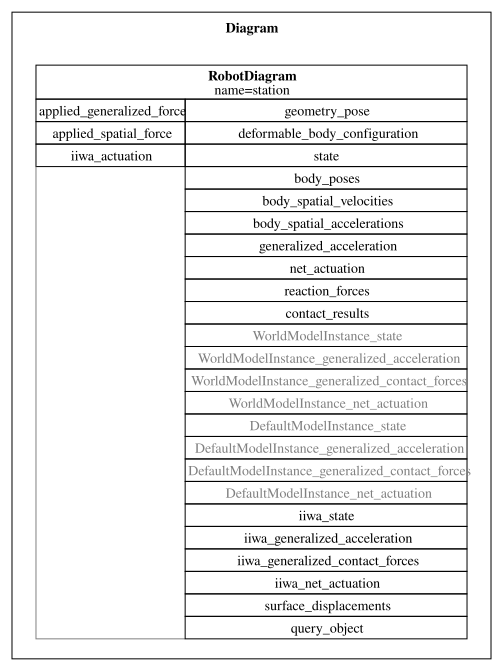

In [6]:
diagram = create_IIWA14_with_hardware_station()
RenderDiagram(diagram, max_depth=1)

In [7]:
print(f"Check your Meshcat window ({meshcat.web_url()}) to see the robot simulation!")

# Let us also simulate the simple IIWA14 setup to make sure it works as expected!
# TODO: Create a context for the diagram

# TODO: Create a simulator

# TODO: Set real-time rate to 1.0

# TODO: Run simulation for 15 seconds

Check your Meshcat window (http://localhost:7001) to see the robot simulation!


---

## Part 2: Bimanual IIWA setup

Great! To highlight how easy it is to modify a scene using scenario directives, let's add another IIWA14 to the scene.

**YOUR TASK:** Create a new scenario with two IIWA14 robots, each welded to the world at different positions.


**Key concept:** Scenario files make it simple and flexible to modify your scene—adding robots, changing positions, or updating configurations can be done with just a few lines.


**Reference:** To understand how to write scenario directives and use the functions above, we recommend looking at the [Bimanual Manipulation Example](https://colab.research.google.com/github/RussTedrake/manipulation/blob/master/book/robot/bimanual.ipynb).


In [8]:
def create_bimanual_IIWA14_with_hardware_station() -> Diagram:
    scenario_string = f"""directives:
- add_model:
    name: iiwa_left
    file: {IIWA_URI}
- add_weld:
    parent: world
    child: iiwa_left::iiwa_link_0
- add_model:
    name: iiwa_right
    file: {IIWA_URI}
- add_weld:
    parent: world
    child: iiwa_right::iiwa_link_0
    X_PC:
        translation: [0.0, 1.0, 0.0]
"""
    scenario = LoadScenario(data=scenario_string)
    station = MakeHardwareStation(scenario, meshcat=meshcat)
    builder = DiagramBuilder()
    station = builder.AddSystem(station)
    return builder.Build()


In [9]:
# Use this to test your implementation if you want!
Grader.grade_output([TestHardwareStationBimanual], [locals()], "results.json")
Grader.print_test_results("results.json")

Total score is 10/10.

Score for Test bimanual IIWA14 HardwareStation creation and structure is 10/10.


Next, let us simulate the setup to make sure it works as expected:

In [10]:
print(f"Check your Meshcat window ({meshcat.web_url()}) to see the robot simulation!")

# Let us also simulate the simple IIWA14 setup to make sure it works as expected!
# TODO: Create a context for the station
# TODO: Create a simulator
# TODO: Set real-time rate to 1.0
# TODO: Run simulation for 15 seconds

Check your Meshcat window (http://localhost:7001) to see the robot simulation!


---

## Part 3: Custom Assets with Scenario Files and Model Directives

Now let's learn how to use scenario files to load your custom assets! We'll create scenario YAML files that can reference your custom models and load them into `HardwareStation`.

**YOUR TASK:** Create scenario files from scratch and load your custom assets using model directives.

**Goal:** Export a video of the simulation with the bimanual IIWA14 setup and your assets, and upload it to Gradescope.

**Reference:** To understand how to write scenario directives and use the functions above, we recommend looking at the [Bimanual Manipulation Example](https://colab.research.google.com/github/RussTedrake/manipulation/blob/master/book/robot/bimanual.ipynb).


First, let us make sure that we have our letters generated in the right folder. Run the code below. Feel free to change the letter properties!

In [11]:
# Let us save our files to a new folder called `assets` in the `Files`
# section on the left
output_dir = Path("assets/")

# TODO: Insert your initials here!
your_initials = "BPG"

for letter in your_initials:
    create_sdf_asset_from_letter(
        text=letter,
        font_name="DejaVu Sans",
        letter_height_meters=0.2,
        extrusion_depth_meters=0.07,
        output_dir=output_dir / f"{letter}_model",
    )

In order to load assets using the model directives we need to have them as local files. Let us save our table asset from the previous notebook to a local file. Fill out the missing code below:

In [12]:
table_sdf = """<?xml version="1.0"?>
<sdf version="1.7">
  <model name="table">
    <link name="table_link">
      <inertial>
        <pose>0 0 0 0 0 0</pose>
        <mass>1.0</mass>
        <inertia>
          <ixx>0.3341667</ixx><ixy>0</ixy><ixz>0</ixz>
          <iyy>0.3341667</iyy><iyz>0</iyz><izz>0.6666667</izz>
        </inertia>
      </inertial>
      <visual name="visual"><geometry><box><size>2 2 0.1</size></box></geometry></visual>
      <collision name="collision"><geometry><box><size>2 2 0.1</size></box></geometry></collision>
    </link>
  </model>
</sdf>
"""

table_sdf_path = "assets/table.sdf"
Path("assets").mkdir(exist_ok=True)
with open(table_sdf_path, "w") as f:
    f.write(table_sdf)

# A simple local object used in the full scene (keeps the exercise offline).
object_sdf = """<?xml version="1.0"?>
<sdf version="1.7">
  <model name="mustard_bottle">
    <link name="mustard_bottle_link">
      <inertial>
        <pose>0 0 0 0 0 0</pose>
        <mass>0.2</mass>
        <inertia><ixx>0.0004</ixx><ixy>0</ixy><ixz>0</ixz>
                 <iyy>0.0004</iyy><iyz>0</iyz><izz>0.0002</izz></inertia>
      </inertial>
      <visual name="visual"><geometry><cylinder><radius>0.04</radius><length>0.15</length></cylinder></geometry></visual>
      <collision name="collision"><geometry><cylinder><radius>0.04</radius><length>0.15</length></cylinder></geometry></collision>
    </link>
  </model>
</sdf>
"""
with open("assets/object.sdf", "w") as f:
    f.write(object_sdf)


Great. Now we should be able to load our custom assets, similar to what we did before with the IIWA14 in the scenario directives. To access a local file in the scenario directives, use the following syntax:
- `file://absolute/path/to/your/file.sdf`

For example, for the letter `B` in the (relative) folder `assets` one could use the following f-string:
- `f"file://{Path.cwd()}/assets/B_model/B.sdf"`

**NOTE**: The asset path must be absolute, which is why we call `Path.cwd()` to get the current working directory above! The asset path is also sensitive to spaces and indentation. If you're unable to load your assets, make sure there are no double spaces anywhere!

We want to weld the table to the world so it doesn't fall down.

We also want to specify a default free-body pose for the initials, which you can do as follows (inside an f-string):
```
- add_model:
    name: {YOUR_OBJECT_NAME}
    file: {PATH_TO_OBJECT}
    default_free_body_pose:
        {BASE_LINK_NAME}:
            translation: [x_pos, y_pos, z_pos]
            rotation: !Rpy {{ deg: [x_rot, y_rot, z_rot] }}
```
Make sure to replace:
- `{YOUR_OBJECT_NAME}`: any name you prefer
- `{PATH_TO_OBJECT}`: the path to the `.sdf` or `.urdf` file (can be either a local file or the path in the `package` repo, like `drake-models`)
- `{BASE_LINK_NAME}`: the name of the base link in the `.sdf` or `.urdf` file.

For instance, for the letter `B`, you could do (within an f-string):

```
- add_model:
    name: B_letter
    file: file://{Path.cwd()/assets/B_model.sdf}
    default_free_body_pose:
        B_body_link:
            translation: [0, 1.0, 0.75]
            rotation: !Rpy {{ deg: [42, 33, 18] }}
```

In addition, we want to load an object from [drake-models](https://github.com/RobotLocomotion/models), 
also specified as a free-floating body (for instance one of [these objects](https://github.com/RobotLocomotion/models/tree/master/ycb))

**To summarize, here is everything you need to do for the scene you should create below:**
- Load two Kuka IIWA14 robots with default joint positions, welded to the world frame
- Load the table from the local `.sdf` file, welded to the world frame
- Load your letter initials from the local `.sdf` files, with default free-body poses 
- Load one or more objects from [drake-models](https://github.com/RobotLocomotion/models) into your scene, with default free-body poses

In [13]:
def create_bimanual_IIWA14_with_table_and_initials_and_assets() -> (
    tuple[Diagram, RobotDiagram]
):
    cwd = Path.cwd()
    (cwd / "assets").mkdir(exist_ok=True)
    table_uri = "file://" + str((cwd / "assets" / "table.sdf").resolve())
    object_uri = "package://drake_models/ycb/006_mustard_bottle.sdf"
    letter_uris = {
        letter: "file://" + str((cwd / "assets" / f"{letter}_model" / f"{letter}.sdf").resolve())
        for letter in your_initials
    }

    letter_blocks = ""
    for i, letter in enumerate(your_initials):
        letter_blocks += f"""- add_model:
    name: {letter}_letter
    file: {letter_uris[letter]}
    default_free_body_pose:
        {letter}_body_link:
            translation: [{0.7 + 0.2 * i}, 0.0, 1.0]
"""

    scenario_yaml = f"""directives:
- add_model:
    name: iiwa_left
    file: {IIWA_URI}
- add_weld:
    parent: world
    child: iiwa_left::iiwa_link_0
- add_model:
    name: iiwa_right
    file: {IIWA_URI}
- add_weld:
    parent: world
    child: iiwa_right::iiwa_link_0
    X_PC:
        translation: [0.0, 1.0, 0.0]
- add_model:
    name: table
    file: {table_uri}
- add_weld:
    parent: world
    child: table::table_link
    X_PC:
        translation: [0.5, 0.0, -0.05]
{letter_blocks}- add_model:
    name: mustard_bottle
    file: {object_uri}
    default_free_body_pose:
        base_link_mustard:
            translation: [0.5, 0.0, 0.75]
"""
    scenario_path = cwd / "assets" / "full_scene.yaml"
    scenario_path.write_text(scenario_yaml)
    scenario = LoadScenario(filename=str(scenario_path))
    station = MakeHardwareStation(scenario, meshcat=meshcat)

    builder = DiagramBuilder()
    station = builder.AddSystem(station)
    diagram = builder.Build()
    return diagram, station


Let us visualize the block diagram:

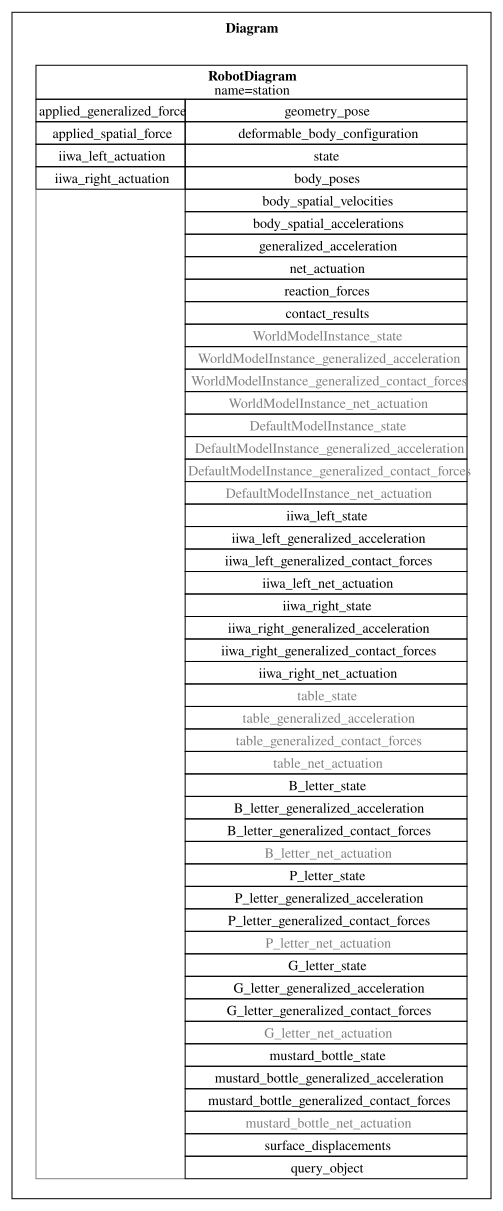

In [14]:
diagram, station = create_bimanual_IIWA14_with_table_and_initials_and_assets()
RenderDiagram(diagram, max_depth=1)

Let's run a quick simulation to see the HardwareStation in action:


In [15]:
def simulate_full_system(
    iiwa_left_q0: np.ndarray,
    iiwa_right_q0: np.ndarray,
    letter_poses: list[RigidTransform],
    object_poses: list[RigidTransform],
    simulation_time: float = 3.0,
    use_realtime: bool = True,
) -> None:
    diagram, station = create_bimanual_IIWA14_with_table_and_initials_and_assets()
    simulator = Simulator(diagram)
    root_context = simulator.get_mutable_context()
    plant = station.GetSubsystemByName("plant")
    plant_context = plant.GetMyMutableContextFromRoot(root_context)

    left = plant.GetModelInstanceByName("iiwa_left")
    right = plant.GetModelInstanceByName("iiwa_right")
    plant.SetPositions(plant_context, left, iiwa_left_q0)
    plant.SetPositions(plant_context, right, iiwa_right_q0)

    for letter, pose in zip(your_initials, letter_poses):
        model = plant.GetModelInstanceByName(f"{letter}_letter")
        body = plant.GetRigidBodyByName(f"{letter}_body_link", model)
        plant.SetFreeBodyPose(plant_context, body, pose)

    object_model = plant.GetModelInstanceByName("mustard_bottle")
    object_body = plant.GetRigidBodyByName("base_link_mustard", object_model)
    plant.SetFreeBodyPose(plant_context, object_body, object_poses[0])

    if use_realtime:
        simulator.set_target_realtime_rate(1.0)
    simulator.Initialize()
    simulator.AdvanceTo(simulation_time)


In [16]:
# Test your simulation
print(f"Check your Meshcat window ({meshcat.web_url()}) to see the robot simulation!")
print("Running HardwareStation simulation...")

meshcat.StartRecording()
simulate_full_system(
    iiwa_left_q0=np.array([0, 0, 0, 0, 0, 0, 0]),
    iiwa_right_q0=np.array([0, 0, 0, 0, 0, 0, 0]),
    # NOTE: Here we have provided the initial poses for three letters, and one object, as
    # an example. Change these to match your setup!
    letter_poses=[
        # You can add rotations to the RigidTransform if you want, but we will learn more about that later!
        # The letters should be placed such that they are not in collision with each other, and such that
        # they fall onto the table.
        RigidTransform([0.7, 0.0, 1.0]),
        RigidTransform([0.9, 0.0, 1.0]),
        RigidTransform([1.1, 0.0, 1.0]),
    ],
    object_poses=[
        RigidTransform([0.5, 0.0, 0.75]),
    ],
    simulation_time=5.0 if running_as_notebook else 5.0,
    use_realtime=running_as_notebook,
)
meshcat.StopRecording()
meshcat.PublishRecording()

print("HardwareStation simulation completed!")

Check your Meshcat window (http://localhost:7001) to see the robot simulation!
Running HardwareStation simulation...


HardwareStation simulation completed!


---

# Congratulations!

You've successfully completed the notebook on **HardwareStation and Advanced Scenarios**! You've learned:

- **HardwareStation** - A convenient high-level tool that automates complex robot setup
- **Scenario files** - Declarative YAML-based scene configuration  
- **Custom assets** - Loading your own models into scenarios  

---

# VERIFICATION IN GRADESCOPE
Congratulations! You are all done with this notebook. Now play the simulation back in your browser, and upload a screen recording of it in Gradescope.


In [17]:
from manipulation.exercises.grader import Grader
from manipulation.exercises.intro.test_hardwarestation_and_scenarios import (
    TestHardwareStationFullSystem,
)

Grader.grade_output([TestHardwareStationFullSystem], [locals()], "results.json")
Grader.print_test_results("results.json")


Total score is 30/30.

Score for Test creation of full system with table and initials is 15/15.

Score for Test that simulate_full_system function runs without errors is 15/15.
